# Final Model Preprocessing

The final model uses machine operating measurements and product type as
predictor variables. Identifier fields and individual failure-mode indicators
are excluded because they would not represent useful operating measurements
for predicting machine failure.

In [5]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

df = pd.read_csv("../data/ai4i2020.csv")

features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

print(X.shape)
print(y.value_counts())

(10000, 6)
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (8000, 6)
Test set: (2000, 6)

Training target distribution:
Machine failure
0    0.966125
1    0.033875
Name: proportion, dtype: float64

Test target distribution:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ["Type"]

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        random_state=42,
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    for name, model in models.items()
}

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = {}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred)
    }

In [7]:
import pandas as pd

results_df = pd.DataFrame(results).T
results_df

,Accuracy,Precision,Recall,F1
Logistic Regression,0.8245,0.141772,0.823529,0.241901
Decision Tree,0.9790,0.732143,0.602941,0.661290
Random Forest,0.9780,0.687500,0.647059,0.666667


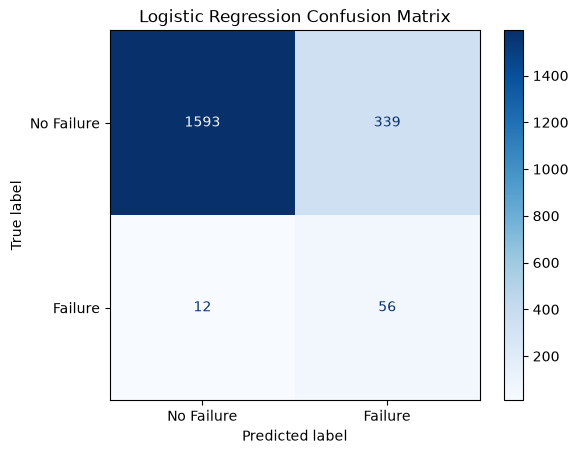

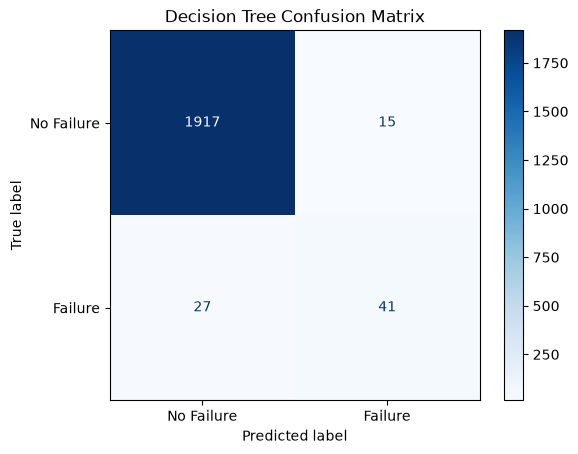

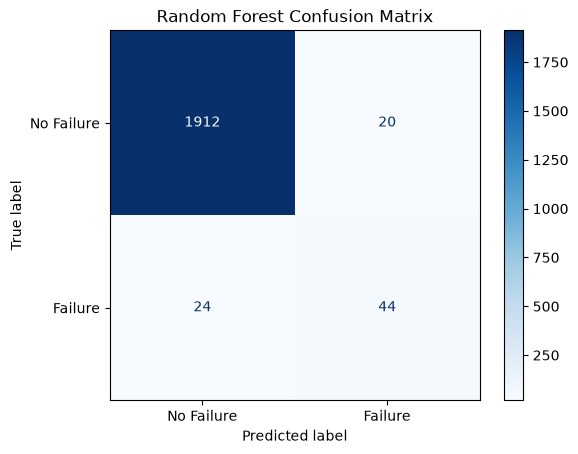

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No Failure", "Failure"],
        cmap="Blues"
    )

    plt.title(f"{name} Confusion Matrix")
    plt.show()

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_pipeline = pipelines["Random Forest"]

# Probability that each test observation belongs to the failure class
y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.50, 0.45, 0.40, 0.35, 0.30]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold),
        "F1": f1_score(y_test, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,Threshold,Accuracy,Precision,Recall,F1
0,0.50,0.9770,0.661765,0.661765,0.661765
1,0.45,0.9765,0.640000,0.705882,0.671329
2,0.40,0.9755,0.611765,0.764706,0.679739
3,0.35,0.9720,0.563830,0.779412,0.654321
4,0.30,0.9670,0.509259,0.808824,0.625000


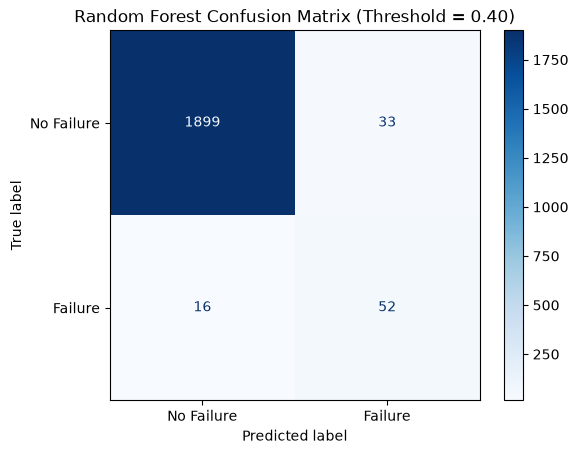

              precision    recall  f1-score   support

  No Failure       0.99      0.98      0.99      1932
     Failure       0.61      0.76      0.68        68

    accuracy                           0.98      2000
   macro avg       0.80      0.87      0.83      2000
weighted avg       0.98      0.98      0.98      2000



In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

final_model = pipelines["Random Forest"]
failure_threshold = 0.40

y_prob = final_model.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob >= failure_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    display_labels=["No Failure", "Failure"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix (Threshold = 0.40)")
plt.show()

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["No Failure", "Failure"]
    )
)

In [16]:
import joblib

from pathlib import Path

Path("../models").mkdir(exist_ok=True)

joblib.dump(
    final_model,
    "../models/random_forest_pipeline.joblib"
)

final_model = pipelines["Random Forest"]

joblib.dump(final_model, "../models/random_forest_pipeline.joblib")

['../models/random_forest_pipeline.joblib']

In [17]:
loaded_model = joblib.load(
    "../models/random_forest_pipeline.joblib"
)

loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]
loaded_predictions = (
    loaded_probabilities >= 0.40
).astype(int)

print(
    "Predictions identical:",
    (loaded_predictions == y_pred_final).all()
)

Predictions identical: True


# Final Model Selection

The Random Forest classifier was selected as the final model because it
provided a strong balance between identifying machine failures and limiting
false-positive predictions. Because machine failures represent only a small
portion of the dataset, accuracy alone was not used to evaluate model
performance.

A classification threshold of 0.40 was selected to increase sensitivity to
potential machine failures. On the test dataset, the final model achieved
97.55% accuracy, 61.18% precision, 76.47% recall, and an F1 score of 67.97%
for the failure class. The model correctly identified 52 of the 68 machine
failures in the test dataset, while producing 33 false-positive predictions
and 16 false-negative predictions.

In [19]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get failure probabilities from the final model
y_prob = final_model.predict_proba(X_test)[:, 1]

# Apply the same threshold used by the Streamlit app
y_pred_40 = (y_prob >= 0.40).astype(int)

precision = precision_score(y_test, y_pred_40)
recall = recall_score(y_test, y_pred_40)
f1 = f1_score(y_test, y_pred_40)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Precision: {precision:.1%}")
print(f"Recall:    {recall:.1%}")
print(f"F1 Score:  {f1:.1%}")
print(f"ROC-AUC:   {roc_auc:.3f}")

Precision: 61.2%
Recall:    76.5%
F1 Score:  68.0%
ROC-AUC:   0.963
